# K3: vektori reči + SVM + SMOTE (tvitovi avio-kompanijama)
**Tip:** Blok 3. Reprezentacija: vektori reči iz `en_core_web_md` (prosek vektora reči). Klasifikator: SVM. Balansiranje: SMOTE.

### Zadatak
U fajlu `Tweets.csv` su tvitovi putnika upućeni američkim avio-kompanijama, sa ručno označenim sentimentom.
- Od kolone `airline_sentiment` napraviti izlaznu varijablu `sentiment` (negativan, neutralan, pozitivan).
- Transformisati kolonu `text` primenom **vektora reči iz spaCy medium modela**. Tvit predstaviti kao prosek vektora reči posle čišćenja (izbaciti i pominjanja korisnika sa `@`).
- Prvi model: **SVC(kernel='linear', C=1)** uz **SMOTE** između vektorizacije i klasifikatora (imblearn Pipeline).
- Metrike po klasama i ukupno, balanced accuracy, matrica konfuzije. Interpretirati: koja klasa je najslabija i sa kojom se meša.
- Drugi model: komentar sa opsezima, pa podešavanje **C i kernel** (vektori reči nemaju hiperparametre transformacije) kroz 5-fold kros-validaciju.
- Uporediti `best_score_` sa macro F1 na testu, pa uporediti modele.

In [1]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder, MinMaxScaler, FunctionTransformer
from sklearn import metrics
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline   # imblearn Pipeline radi i bez SMOTE-a, pa moze da ostane uvek

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path
from IPython.display import display

import spacy

RAND_STATE = 1
DATA_DIR = Path.cwd().parent / 'data'

### Šta je urađeno
- Učitani podaci, izbačeni tvitovi bez teksta i duplikati teksta (ne `dropna()` bez argumenata, jer kolone kao `negativereason` su prazne kod svih pozitivnih i neutralnih tvitova).
- Uzet uzorak od 4000 tvitova (`random_state=1`) zbog brzine.
- Napravljena izlazna varijabla `sentiment` (negativnih je oko 63%).
- Pregledane ostale kolone: `retweet_count` (kdeplot), `airline`, `tweet_location`, `user_timezone` (broj vrednosti i nedostajućih).
- Odluka: ulaz je samo `text`. `negativereason` i `airline_sentiment_confidence` bi bile curenje podataka (nastaju tek kad se sentiment označi).
- Podela 80:20 sa `stratify`.

In [2]:
data = pd.read_csv(DATA_DIR / 'Tweets.csv')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet_created                 14640 non-null  object 
 13  t

In [3]:
data = data.dropna(subset=['text'])
print('Duplikati teksta:', data.duplicated(subset='text').sum())
data = data.drop_duplicates(subset='text')
data = data.sample(n=4000, random_state=RAND_STATE).reset_index(drop=True)
print(data.shape)

Duplikati teksta: 213
(4000, 15)


In [4]:
sentiment_map = {'negative': 'negativan', 'neutral': 'neutralan', 'positive': 'pozitivan'}
data['sentiment'] = data['airline_sentiment'].map(sentiment_map)
print(data['sentiment'].value_counts())
print(data['sentiment'].value_counts(normalize=True))

sentiment
negativan    2541
neutralan     808
pozitivan     651
Name: count, dtype: int64
sentiment
negativan    0.63525
neutralan    0.20200
pozitivan    0.16275
Name: proportion, dtype: float64


In [ ]:
#vidimo da dominira negativna klasa dominatna samim tim ocekujumu veluku preciznost na njoj , a pozitivna klasa je dosta slaba i dataset je jako nebalansiran ocekujemo jako mali odziv za pozitivnu klasu i generalno da Macro F1 bude dosta gori od weighted F1

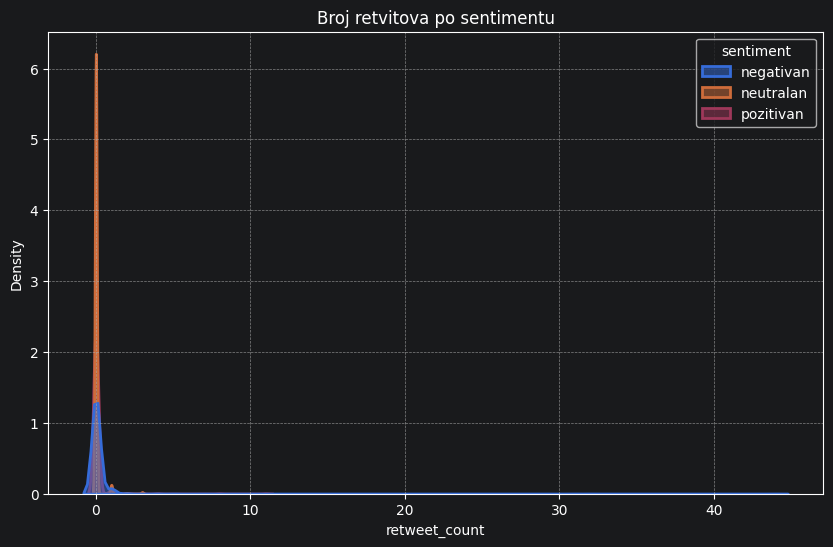

retweet_count
0    3805
1     163
2      14
3       6
4       4
Name: count, dtype: int64
                broj_vrednosti  nedostaje
airline                      6          0
tweet_location            1374       1312
user_timezone               59       1309


In [5]:
plt.figure(figsize=(10, 6))
sb.kdeplot(data=data, x='retweet_count', hue='sentiment',
           fill=True, common_norm=False, alpha=0.5, linewidth=2)
plt.title('Broj retvitova po sentimentu')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

print(data['retweet_count'].value_counts().head())
print(pd.DataFrame({'broj_vrednosti': data[['airline', 'tweet_location', 'user_timezone']].nunique(),
                    'nedostaje': data[['airline', 'tweet_location', 'user_timezone']].isna().sum()}))

In [6]:
X = data['text']
y = data['sentiment']
y_encodings, y_levels = pd.factorize(y)
print(list(y_levels))

X_train, X_test, y_train, y_test = train_test_split(X, y_encodings,
                                                    test_size=0.2,
                                                    random_state=RAND_STATE,
                                                    stratify=y_encodings)
print(X_train.shape, X_test.shape)

['negativan', 'neutralan', 'pozitivan']
(3200,) (800,)


---
# ▶ OVDE KREĆEŠ

Sve iznad je gotovo. Od ove ćelije pa nadalje kucaš sam: kod, komentare u markdown ćelijama i tumačenja.

**Tvoji koraci:**




In [7]:
#radimo vektorizaciju preko vektora reci

In [6]:
#imamo jednu kolonu ulaznu treba  nam smote na trening skupu  , imamo nebalansiran dataset samim tim smote ce pomoci da podigne odziv ali opasce prezinost.

In [8]:
nlp=spacy.load('en_core_web_md',disable=['parser','ner'])

In [9]:
def spacy_srediTekst(doc):
    ocisceniTokeni=[]
    tokens=nlp(doc)
    for token in tokens:
        lemma_lower=token.lemma_.lower()
        if lemma_lower in ['no','not']:
            ocisceniTokeni.append(lemma_lower)
            continue
        if token.is_stop or token.is_space or token.is_punct or token.like_email or token.like_url or token.like_num:
            continue
        ocisceniTokeni.append(lemma_lower)
    return ocisceniTokeni

In [10]:
def vrati_vektore_func(redovi):
    vektori=[]
    for red in redovi:
        vektori.append(nlp(' '.join(spacy_srediTekst(red))).vector)

    return np.array(vektori)

In [11]:
#vectorizer , smote , classifier svc u pipelinu ...
vectorizer=FunctionTransformer(vrati_vektore_func)

In [12]:
smote=SMOTE(random_state=42)
cls=SVC(C=1.0,kernel="linear",class_weight='balanced',decision_function_shape='ovo')

In [13]:
pipe=Pipeline([
    ('vectorizer',vectorizer),
    ('smote',smote),
    ('cls',cls)
])

In [14]:
model1=pipe.fit(X_train,y_train)

In [15]:
y_pred=model1.predict(X_test)

In [19]:
print(classification_report(y_test, y_pred, target_names=y_levels))

              precision    recall  f1-score   support

   negativan       0.83      0.65      0.72       508
   neutralan       0.38      0.56      0.45       162
   pozitivan       0.51      0.65      0.57       130

    accuracy                           0.63       800
   macro avg       0.57      0.62      0.58       800
weighted avg       0.68      0.63      0.65       800



In [32]:
params={
    'cls__C':[0.01,10,100],
    'cls__decision_function_shape':['ovr','ovo']
}

In [33]:
cv=GridSearchCV(pipe,cv=5,param_grid=params,verbose=2,scoring='f1_macro')

In [34]:
model2=cv.fit(X_train,y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV] END ......cls__C=0.01, cls__decision_function_shape=ovr; total time=  21.7s
[CV] END ......cls__C=0.01, cls__decision_function_shape=ovr; total time=  22.2s
[CV] END ......cls__C=0.01, cls__decision_function_shape=ovr; total time=  23.2s
[CV] END ......cls__C=0.01, cls__decision_function_shape=ovr; total time=  22.5s
[CV] END ......cls__C=0.01, cls__decision_function_shape=ovr; total time=  21.9s
[CV] END ......cls__C=0.01, cls__decision_function_shape=ovo; total time=  23.2s
[CV] END ......cls__C=0.01, cls__decision_function_shape=ovo; total time=  23.8s
[CV] END ......cls__C=0.01, cls__decision_function_shape=ovo; total time=  22.5s
[CV] END ......cls__C=0.01, cls__decision_function_shape=ovo; total time=  21.1s
[CV] END ......cls__C=0.01, cls__decision_function_shape=ovo; total time=  21.3s
[CV] END ........cls__C=10, cls__decision_function_shape=ovr; total time=  21.5s
[CV] END ........cls__C=10, cls__decision_functio

In [36]:
model_2=model2.best_estimator_

In [37]:
y_pred_2=model_2.predict(X_test)

In [38]:
print(classification_report(y_test, y_pred_2, target_names=y_levels))

              precision    recall  f1-score   support

   negativan       0.82      0.71      0.76       508
   neutralan       0.37      0.49      0.42       162
   pozitivan       0.53      0.61      0.57       130

    accuracy                           0.65       800
   macro avg       0.57      0.60      0.58       800
weighted avg       0.68      0.65      0.66       800



In [40]:
def get_model_metrics(y_true:np.ndarray, y_pred:np.ndarray, model_name:str):

    # compute P, R, F1 for both averages
    report = classification_report(y_true, y_pred, output_dict=True)

    # compute balanced accuracy
    b_acc = balanced_accuracy_score(y_true, y_pred)

    # extract metrics for the specified averages
    macro_avg = report['macro avg']
    weighted_avg = report['weighted avg']

    results = {
        'Model': model_name,
        'Macro Precision': macro_avg['precision'],
        'Macro Recall': macro_avg['recall'],
        'Macro F1-Score': macro_avg['f1-score'],
        'Weighted Precision': weighted_avg['precision'],
        'Weighted Recall': weighted_avg['recall'],
        'Weighted F1-Score': weighted_avg['f1-score'],
        'Balanced Accuracy': b_acc
    }

    return results

In [59]:
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_test, y_test)
dummy_pred=dummy_clf.predict(X_test)

In [60]:
pd.DataFrame([
    get_model_metrics(y_test, y_pred, "Pocetni model"),
    get_model_metrics(y_test, y_pred_2, "Poboljsan model"),
    get_model_metrics(y_test, dummy_pred, "Dummy model")
]).round(2)

C:\Users\INSOMNIA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\INSOMNIA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\INSOMNIA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _war

,Model,Macro Precision,Macro Recall,Macro F1-Score,Weighted Precision,Weighted Recall,Weighted F1-Score,Balanced Accuracy
0,Pocetni model,0.57,0.62,0.58,0.68,0.63,0.65,0.62
1,Poboljsan model,0.57,0.60,0.58,0.68,0.65,0.66,0.60
2,Dummy model,0.21,0.33,0.26,0.40,0.64,0.49,0.33
